In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmc
from matplotlib.colors import LogNorm

plt.style.use("../plotstyling.mplstyle")

import warnings
warnings.filterwarnings("ignore", message=".*date/calendar/year zero convention.*")

In [3]:
data_dir = "/data/s6/L2_ext/CDS_C3S_CLOUD/2026/04/"

filepath = data_dir + "2026/04/25/53049/C3S-312bL1-L2-CLOUD-CLD-SLSTR_ORAC_Sentinel3a_202604250123_53049_R9999.primary.nc"

ds = xr.open_dataset(filepath)

In [5]:

ds_aws = xr.open_dataset("/scratch/may/aws/L2_arctic/2026/04/l2_arctic_20260425005607_20260425023533_v3.nc")

In [6]:
ds_aws

<xarray.Dataset> Size: 19MB
Dimensions:                 (scan: 947, fov: 88, quantile: 5, surface_type: 6,
                             channel: 19)
Coordinates:
  * scan                    (scan) datetime64[ns] 8kB 2026-04-25T00:56:09.404...
  * quantile                (quantile) float32 20B 0.02 0.16 0.5 0.84 0.98
  * surface_type            (surface_type) <U7 168B 'ocean' ... 'glacier'
  * channel                 (channel) <U5 380B 'AWS11' 'AWS12' ... 'AWS44'
    latitude                (scan, fov) float32 333kB ...
    longitude               (scan, fov) float32 333kB ...
Dimensions without coordinates: fov
Data variables: (12/18)
    fwp_mean                (scan, fov) float32 333kB ...
    fwp_most_prob           (scan, fov) float32 333kB ...
    fwp_quantiles           (scan, fov, quantile) float32 2MB ...
    fwp_dm_mean             (scan, fov) float32 333kB ...
    fwp_dm_most_prob        (scan, fov) float32 333kB ...
    fwp_dm_quantiles        (scan, fov, quantile) float32 2MB ...
    ...                      ...
    remap_distance          (scan, fov) float32 333kB ...
    surface_type_fractions  (scan, fov, surface_type) float32 2MB ...
    tb                      (scan, fov, channel) float32 6MB ...
    l1b_index_scans         (scan) uint32 4kB ...
    l1b_index_fovs          (fov) uint32 352B ...
    flag_bad_data           (scan, fov) uint8 83kB ...
Attributes:
    title:        CHIP-AWS: Arctic retrievals
    institution:  Chalmers University of Technology
    references:   n/a
    history:      Retrieval processing

In [7]:
iwp = ds["cwp"].where((ds["phase"] == 2) & (ds["illum"] == 1)) / 1000.0 # kg/m2
lat = ds["lat"].values
lon = ds["lon"].values

In [8]:
raw = xr.open_dataset(f, decode_times=False)
days = raw["time"] - 2451545.0
ds["time"] = np.datetime64("2000-01-01T12:00:00", "ns") + (days * 86400e9).astype("timedelta64[ns]")
print(ds["time"].min().values, ds["time"].max().values)

NameError: name 'f' is not defined

In [13]:
raw = xr.open_dataset(f, decode_times=False)
days = raw["time"] - 2451545.0
ds["time"] = np.datetime64("2000-01-01T12:00:00", "ns") + (days * 86400e9).astype("timedelta64[ns]")
print(ds["time"].min().values, ds["time"].max().values)

NameError: name 'f' is not defined

In [14]:
def style_map(ax, scale="50m"):
    """Same look as the collocation maps, at a fixed level of detail."""
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor="lightgrey", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor="dimgrey", zorder=0)
    ax.add_feature(cfeature.BORDERS.with_scale(scale), edgecolor="white", linewidth=0.5, zorder=1)
    ax.coastlines(resolution=scale, color="white", linewidth=0.8, zorder=10)
    ax.gridlines(draw_labels=False, linewidth=0.3)

fwp_norm = LogNorm(vmin=1e-2, vmax=1e0)
geo = ccrs.PlateCarree()

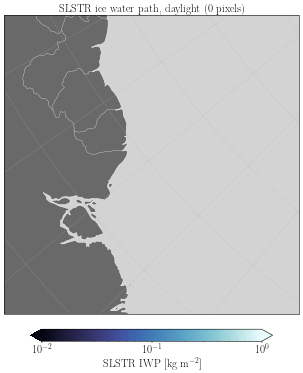

In [15]:

fig, ax = plt.subplots(figsize=(13, 12), subplot_kw={"projection": ccrs.NorthPolarStereo()})
style_map(ax)

lon_lo, lon_hi = np.nanmin(ds["lon"]), np.nanmax(ds["lon"])
lat_lo, lat_hi = np.nanmin(ds["lat"]), np.nanmax(ds["lat"])
ax.set_extent([lon_lo, lon_hi, lat_lo, lat_hi], crs=geo)

mesh = ax.pcolormesh(ds["lon"], ds["lat"], iwp, norm=fwp_norm, cmap=cmc.cm.ice,
                     transform=geo, zorder=2)

ax.set_title(f"SLSTR ice water path, daylight ({int(iwp.notnull().sum())} pixels)")
fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.6, pad=0.04,
             extend="both", label=r"SLSTR IWP [kg m$^{-2}$]")


In [16]:
print("IWP min/max:", float(iwp.min()), float(iwp.max()))
print("Non-NaN IWP pixels:", int(iwp.notnull().sum()))

IWP min/max: nan nan
Non-NaN IWP pixels: 0


In [17]:
print("lat range:", float(ds["lat"].min()), float(ds["lat"].max()))
print("lon range:", float(ds["lon"].min()), float(ds["lon"].max()))
print(ds["time"].min().values, ds["time"].max().values)

lat range: -0.9911190271377563 12.460468292236328
lon range: -57.62599563598633 -42.046424865722656
2027-04-26T01:23:40.149475000 2027-04-26T01:26:39.000084000


In [18]:
import glob
import xarray as xr

files = sorted(glob.glob(data_dir + "2026/01/*/*/*.primary.nc"))



northern = []
for f in files:
    with xr.open_dataset(f) as d:
        lat_max = float(d["lat"].max())
    if lat_max > 60:
        northern.append(f)
        print(f"{lat_max:6.1f}  {f}")

In [ ]:
northern